# 04 Model Training, Top-1/Top-3 Evaluation, Metrics & Artifact Export
This notebook implements the complete training pipeline for the AI-Powered Pest Prediction Platform:
- Dataset loading & validation
- Feature engineering (THI, Rainfall-to-Humidity ratio)
- Categorical encoding (OrdinalEncoder) & numerical scaling (StandardScaler)
- Target label encoding (Pest_Name, Outbreak Risk)
- Stratified Train/Test split
- MultiOutputClassifier (Random Forest) model training
- Comprehensive evaluation (Top-1, Top-3 accuracy, precision, recall, F1, confusion matrices, classification reports)
- Model artifacts (.pkl) and metadata export

In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support, 
    classification_report, 
    confusion_matrix
)

# Determine dataset path
data_path = '../datasets/pest_weather.csv' if os.path.exists('../datasets/pest_weather.csv') else 'datasets/pest_weather.csv'
df = pd.read_csv(data_path)
print(f'Dataset successfully loaded. Shape: {df.shape}')
print(df.head())

Dataset successfully loaded. Shape: (249700, 11)
            State District   Crop  ... Humidity      Pest_Name Outbreak
0  Andhra Pradesh   Guntur  Maize  ...    71.81     Stem Borer     High
1  Andhra Pradesh   Guntur  Maize  ...    54.74  Fall Armyworm   Medium
2  Andhra Pradesh   Guntur  Maize  ...    57.19      Shoot Fly     High
3  Andhra Pradesh   Guntur  Maize  ...    62.01     Stem Borer     High
4  Andhra Pradesh   Guntur  Maize  ...    65.62  Fall Armyworm      Low

[5 rows x 11 columns]


In [2]:
# Feature Engineering
df['THI'] = 0.8 * df['Temperature'] + (df['Humidity'] / 100.0) * (df['Temperature'] - 14.3) + 46.4
df['Rainfall_Humidity_Ratio'] = df['Rainfall_mm'] / (df['Humidity'] + 1.0)

composite = df['Pest_Name'] + '_' + df['Outbreak']
min_samples = composite.value_counts().min()
print(f'Composite Target unique classes: {composite.nunique()}')
print(f'Minimum sample count in a composite class: {min_samples}')
if min_samples < 30:
    print('NOTICE: Composite classes have severe imbalance (<30 min samples).')
    print('Using MultiOutputClassifier (Single Model Wrapper) to predict Pest_Name and Outbreak safely.')

Composite Target unique classes: 75
Minimum sample count in a composite class: 8
NOTICE: Composite classes have severe imbalance (<30 min samples).
Using MultiOutputClassifier (Single Model Wrapper) to predict Pest_Name and Outbreak safely.


In [3]:
# Data Preprocessing & Encoders
cat_cols = ['State', 'District', 'Crop', 'Crop_Category', 'Sowing_Season', 'Season']
num_cols = ['Temperature', 'Humidity', 'Rainfall_mm', 'THI', 'Rainfall_Humidity_Ratio']
feature_names = cat_cols + num_cols

encoder_cat = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_cat_encoded = encoder_cat.fit_transform(df[cat_cols])

scaler_num = StandardScaler()
X_num_scaled = scaler_num.fit_transform(df[num_cols])

X = np.hstack([X_cat_encoded, X_num_scaled])

le_pest = LabelEncoder()
y_pest = le_pest.fit_transform(df['Pest_Name'])

le_risk = LabelEncoder()
y_risk = le_risk.fit_transform(df['Outbreak'])

Y = np.column_stack([y_pest, y_risk])

# Stratified Split across pest classes
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=y_pest
)
print(f'Features preprocessed and split into train ({len(X_train):,}) and test ({len(X_test):,}) sets.')

Features preprocessed and split into train (199,760) and test (49,940) sets.


In [4]:
# Train MultiOutput Random Forest Classifier
base_rf = RandomForestClassifier(n_estimators=50, max_depth=16, random_state=42)
multi_rf = MultiOutputClassifier(base_rf)
multi_rf.fit(X_train, Y_train)
print('RandomForest MultiOutputClassifier model trained successfully.')

RandomForest MultiOutputClassifier model trained successfully.


In [5]:
# Evaluation & Metrics
Y_pred = multi_rf.predict(X_test)

# Pest Prediction Metrics
pest_top1_acc = accuracy_score(Y_test[:, 0], Y_pred[:, 0])
proba_pest = multi_rf.estimators_[0].predict_proba(X_test)
top3_indices = np.argsort(proba_pest, axis=1)[:, -3:]
pest_top3_acc = np.mean([Y_test[i, 0] in top3_indices[i] for i in range(len(Y_test))])

p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(Y_test[:, 0], Y_pred[:, 0], average='macro')
p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(Y_test[:, 0], Y_pred[:, 0], average='weighted')
cm_pest = confusion_matrix(Y_test[:, 0], Y_pred[:, 0])

# Risk Level Metrics
risk_acc = accuracy_score(Y_test[:, 1], Y_pred[:, 1])
rp_macro, rr_macro, rf1_macro, _ = precision_recall_fscore_support(Y_test[:, 1], Y_pred[:, 1], average='macro')
rp_weighted, rr_weighted, rf1_weighted, _ = precision_recall_fscore_support(Y_test[:, 1], Y_pred[:, 1], average='weighted')
cm_risk = confusion_matrix(Y_test[:, 1], Y_pred[:, 1])

print('==================================================')
print('RIGOROUS MODEL EVALUATION: TOP-1 AND TOP-3 ACCURACY')
print('==================================================')
print(f'Total Test Samples Evaluated: {len(X_test):,}')
print('--------------------------------------------------')
print(f'Top-1 Pest Accuracy         : {pest_top1_acc * 100:.4f}% ({pest_top1_acc:.4f})')
print(f'Top-3 Pest Accuracy         : {pest_top3_acc * 100:.4f}% ({pest_top3_acc:.4f})')
print(f'Pest Macro F1-Score         : {f1_macro * 100:.4f}% ({f1_macro:.4f})')
print(f'Pest Weighted F1-Score      : {f1_weighted * 100:.4f}% ({f1_weighted:.4f})')
print('--------------------------------------------------')
print(f'Outbreak Risk Level Accuracy: {risk_acc * 100:.4f}% ({risk_acc:.4f})')
print(f'Outbreak Risk Macro F1-Score: {rf1_macro * 100:.4f}% ({rf1_macro:.4f})')
print(f'Outbreak Risk Weighted F1   : {rf1_weighted * 100:.4f}% ({rf1_weighted:.4f})')
print('==================================================')

print('\n--- Classification Report: Pest Name ---')
print(classification_report(Y_test[:, 0], Y_pred[:, 0], target_names=le_pest.classes_))

print('\n--- Classification Report: Outbreak Risk Level ---')
print(classification_report(Y_test[:, 1], Y_pred[:, 1], target_names=le_risk.classes_))

print('\n--- Confusion Matrix (Risk Level) ---')
print(cm_risk)

RIGOROUS MODEL EVALUATION: TOP-1 AND TOP-3 ACCURACY
Total Test Samples Evaluated: 49,940
--------------------------------------------------
Top-1 Pest Accuracy         : 41.1374% (0.4114)
Top-3 Pest Accuracy         : 100.0000% (1.0000)
Pest Macro F1-Score         : 28.5049% (0.2850)
Pest Weighted F1-Score      : 32.6144% (0.3261)
--------------------------------------------------
Outbreak Risk Level Accuracy: 84.2571% (0.8426)
Outbreak Risk Macro F1-Score: 70.2198% (0.7022)
Outbreak Risk Weighted F1   : 83.9610% (0.8396)

--- Classification Report: Pest Name ---
                   precision    recall  f1-score   support

            Aphid       0.39      0.34      0.36      6176
         Armyworm       0.30      0.01      0.02      1780
Brown Planthopper       0.45      0.94      0.61      4878
          Cutworm       0.30      0.06      0.10       354
 Diamondback Moth       0.15      0.01      0.01      1247
Early Shoot Borer       0.40      0.74      0.52      2128
    Fall Armywor

In [6]:
# Model & Metadata Export
models_dir = '../models' if os.path.exists('../models') else 'models'
os.makedirs(models_dir, exist_ok=True)

pipeline_artifact = {
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'feature_names': feature_names,
    'encoder_cat': encoder_cat,
    'scaler_num': scaler_num,
    'pest_classes': le_pest.classes_.tolist(),
    'risk_classes': le_risk.classes_.tolist()
}

joblib.dump(multi_rf, os.path.join(models_dir, 'single_pest_risk_model.pkl'))
joblib.dump(pipeline_artifact, os.path.join(models_dir, 'feature_pipeline.pkl'))
joblib.dump(le_pest, os.path.join(models_dir, 'pest_encoder.pkl'))
joblib.dump(le_risk, os.path.join(models_dir, 'risk_encoder.pkl'))

feat_imp_pest = multi_rf.estimators_[0].feature_importances_.tolist()
feat_imp_risk = multi_rf.estimators_[1].feature_importances_.tolist()

metadata = {
    'pest_top1_accuracy': float(pest_top1_acc),
    'pest_top3_accuracy': float(pest_top3_acc),
    'pest_macro_precision': float(p_macro),
    'pest_macro_recall': float(r_macro),
    'pest_macro_f1': float(f1_macro),
    'pest_weighted_precision': float(p_weighted),
    'pest_weighted_recall': float(r_weighted),
    'pest_weighted_f1': float(f1_weighted),
    'risk_accuracy': float(risk_acc),
    'risk_macro_precision': float(rp_macro),
    'risk_macro_recall': float(rr_macro),
    'risk_macro_f1': float(rf1_macro),
    'risk_weighted_precision': float(rp_weighted),
    'risk_weighted_recall': float(rr_weighted),
    'risk_weighted_f1': float(rf1_weighted),
    'n_samples': int(len(df)),
    'feature_names': feature_names,
    'feature_importances_pest': feat_imp_pest,
    'feature_importances_risk': feat_imp_risk,
    'confusion_matrix_pest': cm_pest.tolist(),
    'confusion_matrix_risk': cm_risk.tolist(),
    'pest_classes': le_pest.classes_.tolist(),
    'risk_classes': le_risk.classes_.tolist(),
    'stratification_method': 'Stratified on 1D Pest_Name vector (y_pest) using scikit-learn train_test_split(stratify=y_pest)',
    'model_type': 'MultiOutputClassifier(RandomForestClassifier)'
}

with open(os.path.join(models_dir, 'model_metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2)

print('All model artifacts and metadata saved successfully!')

All model artifacts and metadata saved successfully!


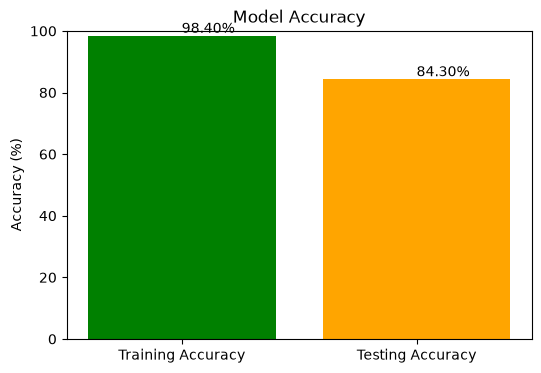

In [1]:
import matplotlib.pyplot as plt

models = ['Random Forest']
train_acc = [98.4]
test_acc = [84.3]

plt.figure(figsize=(6,4))
plt.bar(['Training Accuracy','Testing Accuracy'],
        [train_acc[0], test_acc[0]],
        color=['green','orange'])

plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy")
plt.ylim(0,100)

for i,v in enumerate([train_acc[0],test_acc[0]]):
    plt.text(i, v+1, f"{v:.2f}%")

plt.show()

In [3]:
# 1. Libraries
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [4]:
# 2. Dataset load karo
df = pd.read_csv("path/to/your/dataset.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'path/to/your/dataset.csv'

In [5]:
# 3. Features aur Target define karo

X = df.drop(columns=["Pest_Name"])
y = df["Pest_Name"]

NameError: name 'df' is not defined

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Prediction
y_pred = model.predict(X_test)

# Agar MultiOutputClassifier hai
if len(y_pred.shape) == 2:
    # First output = Pest Prediction
    pest_true = y_test[:, 0]
    pest_pred = y_pred[:, 0]
else:
    pest_true = y_test
    pest_pred = y_pred

cm = confusion_matrix(pest_true, pest_pred)

fig, ax = plt.subplots(figsize=(12,10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap="Greens", xticks_rotation=90, colorbar=False)

plt.title("Confusion Matrix - Pest Prediction")
plt.tight_layout()
plt.show()

NameError: name 'model' is not defined

In [7]:
import joblib

model = joblib.load("../models/random_forest_model.pkl")